# STEAM-GAME-PROJECT — Phân tích Q4

Q4 là câu hỏi nghiên cứu thứ ba trong template non-ML (RQ3).

## 3.3.3. Xây dựng câu hỏi nghiên cứu — Quy mô DLC và hệ thống thành tựu

### 1. Câu hỏi nghiên cứu

> Ở các trò chơi có ít nhất một DLC, tổng số thành tựu (achievements) tăng nhanh hay chậm hơn số DLC khi quy mô DLC tăng? Xu hướng này có còn khi so sánh các trò chơi cùng thể loại và cùng giai đoạn phát hành không?

**Người phụ trách — Võ Nguyễn Vân Anh (24127016).**

### 2. Động cơ nghiên cứu

Ở notebook 01, trung vị tổng thành tựu cao hơn trong các nhóm có nhiều DLC. Nhóm muốn biết mức tăng thành tựu có theo kịp mức tăng số DLC hay không. Khi lên kế hoạch cho game có nhiều DLC, nhà thiết kế có thể dùng mức tăng ở các game cùng thể loại và giai đoạn phát hành làm mốc tham khảo để xem xét quy mô hệ thống thành tựu.

### 3. Thuộc tính sử dụng

| Cột trong CSV tháng 03/2025 | Vai trò |
| --- | --- |
| `appid` | Khóa game, một dòng cho mỗi game trong mô hình chính. |
| `dlc_count` | Số DLC của game. |
| `achievements` | Tổng thành tựu của game, kể cả 0. |
| `genres` | Các nhãn thể loại. Mỗi game có thể mang nhiều nhãn. |
| `release_date` | Ngày phát hành, dùng để xếp vào giai đoạn. |

### 4. Giả thuyết nghiên cứu

Nếu tổng thành tựu tăng tỷ lệ thuận với số DLC, số DLC gấp đôi sẽ đi cùng mức tăng 100% của tổng thành tựu trung bình. Q4 so sánh với mốc này, sau đó kiểm tra mối liên hệ trong các nhóm thể loại và giai đoạn phát hành.

### 5. Tiêu chí chiều sâu

| Tiêu chí | Cách thực hiện |
| --- | --- |
| **D3** | Thành tựu/DLC để mô tả. Dùng log số DLC để đo độ co giãn và chuyển ngày phát hành thành giai đoạn. |
| **D4** | Xét thể loại và giai đoạn trong mô hình gộp. Kiểm tra riêng các tầng thể loại × giai đoạn đủ lớn. |
| **D5** | Bootstrap theo game để báo khoảng tin cậy 95% cho mức tăng ước lượng. |
| **D6** | So sánh kết quả khi đổi quy tắc giữ ngoại lệ hoặc chỉ xét game có từ 2 DLC. |

### 6. Phạm vi nghiên cứu

`achievements` là tổng cấp game. Phân tích so sánh các game trong một ảnh chụp dữ liệu.

## 3.4.3. Phân tích Q4

### Preprocessing

#### 1. Mục tiêu phân tích

Ước lượng mức thay đổi của tổng thành tựu trung bình khi số DLC gấp đôi, trước và sau khi xét thể loại và giai đoạn phát hành.

#### 2. Chuẩn bị dữ liệu

Đọc năm cột từ `data/processed/steam_games_mar2025.csv` gồm `appid`, `dlc_count`, `achievements`, `genres` và `release_date`. Các giá trị ở cả năm cột đã được đối chiếu theo `appid` và khớp với CSV gốc tháng 03/2025.

#### 3. Tiền xử lý dữ liệu

1. **Kiểm tra AppID và số đếm.** Giữ AppID chỉ gồm chữ số. Nếu có AppID trùng, dừng để kiểm tra bản ghi. Số DLC và tổng thành tựu phải là số nguyên không âm.
2. **Xác định tập game cho Q4.** Giữ game có ít nhất một DLC, kể cả game có 0 thành tựu. Như vậy, tỷ số thành tựu/DLC luôn có mẫu số dương.
3. **Chuẩn hóa thể loại và ngày phát hành.** Bỏ nhãn rỗng và nhãn trùng trong từng game, đồng thời giữ các thể loại hợp lệ còn lại. Xếp game theo các giai đoạn phát hành của notebook 01. Giữ game thiếu thể loại hoặc ngày phát hành và ghi nhận riêng các trường hợp này.
4. **Tạo biến để phân tích.** Dùng `achievements_per_dlc` để mô tả tỷ số thành tựu/DLC và `log_dlc` để ước lượng mức thay đổi khi số DLC gấp đôi.

Bảng dưới ghi số dòng trước và sau từng bước, số dòng bị loại và lý do. Các bước kiểm tra giữ đủ 89.618 game. Loại 75.388 game có 0 DLC, còn 14.230 game. Tập này gồm 2.700 game có 0 thành tựu và 38 game thiếu nhãn thể loại. Tất cả đều có ngày phát hành hợp lệ.

In [1]:
%matplotlib inline

from ast import literal_eval
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
from matplotlib.lines import Line2D
from threadpoolctl import threadpool_limits

plt.rcParams["font.family"] = "DejaVu Sans"

csv = Path("data/processed/steam_games_mar2025.csv")
path = next((p / csv for p in (Path.cwd(), *Path.cwd().parents) if (p / csv).is_file()), None)
if path is None:
    raise FileNotFoundError(f"Không tìm thấy {csv.as_posix()}.")

columns = ["appid", "dlc_count", "achievements", "genres", "release_date"]
source_data = pd.read_csv(path, usecols=columns, dtype={"appid": "string"})
flow = [("Đọc CSV", len(source_data), len(source_data), "Nạp 5 cột dùng cho Q4")]


def keep(frame, mask, step, reason):
    kept = frame.loc[mask].copy()
    flow.append((step, len(frame), len(kept), reason))
    return kept


game = keep(source_data, source_data["appid"].str.fullmatch(r"[0-9]+", na=False),
            "Kiểm tra AppID", "Giữ mã chỉ gồm chữ số")
if game["appid"].duplicated().any():
    raise ValueError("AppID trùng. Kiểm tra bản ghi trước khi tiếp tục.")
flow.append(("Kiểm tra khóa trùng", len(game), len(game), "Một dòng cho mỗi AppID"))

count_cols = ["dlc_count", "achievements"]
game[count_cols] = game[count_cols].apply(pd.to_numeric, errors="coerce")
count_data = game[count_cols]
valid = (
    np.isfinite(count_data).all(axis=1)
    & count_data.ge(0).all(axis=1)
    & count_data.mod(1).eq(0).all(axis=1)
)
game = keep(game, valid, "Kiểm tra số đếm", "DLC và thành tựu là số nguyên không âm")
game = keep(game, game["dlc_count"].gt(0), "Giữ game có DLC",
            "Q4 xét DLC > 0 và giữ cả achievements = 0")
game[count_cols] = game[count_cols].astype("int64")


def parse_genres(value):
    if not isinstance(value, str):
        return ()
    try:
        labels = literal_eval(value)
    except (SyntaxError, ValueError):
        return ()
    if not isinstance(labels, (list, tuple)):
        return ()
    return tuple(sorted({x.strip() for x in labels if isinstance(x, str) and x.strip()}))


cohort_labels = ["Đến 2009", "2010–2014", "2015–2019", "2020–2022", "2023–2025", "Sau 2025"]
game["release_date"] = pd.to_datetime(game["release_date"], format="%Y-%m-%d", errors="coerce")
game["cohort"] = pd.cut(
    game["release_date"].dt.year, [-np.inf, 2009, 2014, 2019, 2022, 2025, np.inf],
    labels=cohort_labels,
).astype("string").fillna("Không rõ")
game["genre_labels"] = game["genres"].map(parse_genres)
game["achievements_per_dlc"] = game["achievements"] / game["dlc_count"]
game["log_dlc"] = np.log(game["dlc_count"])
flow.append(("Tạo biến dẫn xuất", len(game), len(game),
             "Giữ cả game chưa rõ thể loại hoặc ngày"))
game = game.reset_index(drop=True)

flow_table = pd.DataFrame(flow, columns=["Bước", "Trước", "Sau", "Lý do"])
flow_table.insert(3, "Số bị loại", flow_table["Trước"] - flow_table["Sau"])
display(flow_table)
display(pd.Series({
    "Game có 0 thành tựu": int(game["achievements"].eq(0).sum()),
    "Game thiếu nhãn thể loại": int(game["genre_labels"].map(len).eq(0).sum()),
    "Game thiếu ngày phát hành": int(game["release_date"].isna().sum()),
}, name="Số game").to_frame())
assert len(game) > 0 and game["appid"].is_unique
assert game["dlc_count"].gt(0).all() and game["achievements"].ge(0).all()

,Bước,Trước,Sau,Số bị loại,Lý do
0,Đọc CSV,89618,89618,0,Nạp 5 cột dùng cho Q4
1,Kiểm tra AppID,89618,89618,0,Giữ mã chỉ gồm chữ số
2,Kiểm tra khóa trùng,89618,89618,0,Một dòng cho mỗi AppID
3,Kiểm tra số đếm,89618,89618,0,DLC và thành tựu là số nguyên không âm
4,Giữ game có DLC,89618,14230,75388,Q4 xét DLC > 0 và giữ cả achievements = 0
5,Tạo biến dẫn xuất,14230,14230,0,Giữ cả game chưa rõ thể loại hoặc ngày


,Số game
Game có 0 thành tựu,2700
Game thiếu nhãn thể loại,38
Game thiếu ngày phát hành,0


### Analysis

#### 4. Phân tích khám phá

Giữ các khoảng DLC của notebook 01 để dễ đối chiếu, gồm **1, 2–5, 6–20 và trên 20 DLC**. Trong từng nhóm, báo số game, trung bình, trung vị và hai tứ phân vị Q1 và Q3 của tổng số thành tựu. Cột cuối là trung vị của các tỷ số thành tựu/DLC tính trên từng game. Bảng thứ hai cho biết số game theo giai đoạn phát hành.

In [2]:
dlc_labels = ["1", "2-5", "6-20", "Trên 20"]
game["dlc_group"] = pd.cut(game["dlc_count"], [0, 1, 5, 20, np.inf], labels=dlc_labels)
groups = game.groupby("dlc_group", observed=True).agg(
    n=("appid", "size"), mean=("achievements", "mean"), median=("achievements", "median"),
    q1=("achievements", lambda s: s.quantile(0.25)),
    q3=("achievements", lambda s: s.quantile(0.75)),
    median_per_dlc=("achievements_per_dlc", "median"),
)
display(groups.rename(columns={
    "n": "Số game", "mean": "Trung bình", "median": "Trung vị",
    "q1": "Q1", "q3": "Q3", "median_per_dlc": "Trung vị thành tựu/DLC",
}).round(2))
display(game["cohort"].value_counts().rename("Số game").to_frame())

,Số game,Trung bình,Trung vị,Q1,Q3,Trung vị thành tựu/DLC
dlc_group,,,,,,
1,9007,29.75,17.0,5.0,33.0,17.00
2-5,3978,37.60,28.0,12.0,45.0,10.50
6-20,963,61.18,40.0,15.0,59.0,4.07
Trên 20,282,140.82,42.5,6.0,66.0,1.20


,Số game
cohort,
2015–2019,4911
2020–2022,4362
2023–2025,4252
2010–2014,692
Đến 2009,13


**Nhận xét sau hai bảng**

- **Tổng thành tựu cao hơn ở các nhóm có nhiều DLC.** Trung vị lần lượt là 17, 28, 40 và 42,5. Nhóm trên 20 DLC chỉ có 282 game và có trung bình 140,82, cao hơn nhiều so với trung vị 42,5. Chênh lệch này cho thấy cần xem cả trung vị lẫn trung bình khi mô tả nhóm.
- **Tỷ số thành tựu/DLC giảm qua bốn nhóm.** Trung vị của tỷ số giảm từ 17 ở nhóm một DLC xuống 1,20 ở nhóm trên 20 DLC. Do số DLC cũng nằm ở mẫu số, tỷ số dùng để mô tả. Mục 5 ước lượng tổng thành tựu trung bình thay đổi bao nhiêu khi số DLC gấp đôi, sau khi xét thể loại và giai đoạn phát hành.
- **Cỡ mẫu khác nhau theo giai đoạn.** Mỗi giai đoạn từ 2015 trở đi có hơn 4.000 game, còn nhóm đến năm 2009 chỉ có 13 game. Chênh lệch này là lý do cần kiểm tra cỡ mẫu trước khi ước lượng riêng theo thể loại và giai đoạn.

#### 5. Phân tích thống kê

Dùng hồi quy Poisson với liên kết log để ước lượng **trung bình có điều kiện** của số thành tựu. Cách này giữ được game có 0 thành tựu. Mô hình chính là

$$
\log E(A_i \mid D_i, g_i, t_i)
= \alpha + \beta \log D_i + \gamma^\top g_i + \delta^\top t_i,
$$

với $A_i$ là tổng thành tựu, $D_i$ là số DLC, $g_i$ là các cờ thể loại và $t_i$ là giai đoạn phát hành. Các nhãn có ít nhất 100 game có cờ riêng. Một cờ ghi nhận game mang nhãn hiếm, một cờ ghi nhận game thiếu nhãn. Mỗi game có một dòng trong mô hình gộp.

Mô hình gộp dùng một hệ số $\beta$ chung cho các mức DLC. Khi giữ nguyên các biến còn lại, số DLC gấp đôi tương ứng với mức thay đổi ước lượng $100(2^\beta-1)\%$. Mức 0% ứng với $\beta=0$ và mức tăng cùng tỷ lệ 100% ứng với $\beta=1$.

Chọn ba nhãn phổ biến nhất trên toàn bộ tập phân tích. Với mỗi nhãn, ước lượng riêng trong từng giai đoạn nếu nhóm có ít nhất 200 game và ít nhất ba giá trị DLC khác nhau. Các game trong nhóm cùng mang nhãn đang xét và cùng giai đoạn phát hành. Những nhãn khác của từng game có thể khác nhau, nên một game có thể xuất hiện ở nhiều nhóm thể loại.

Khoảng tin cậy (KTC) 95% của mô hình gộp đã điều chỉnh được tính bằng bootstrap theo game. Mô hình gộp chưa điều chỉnh và các mô hình theo nhóm dùng KTC vững HC0, cho phép phương sai khác trung bình.

In [3]:
genre_counts = Counter(label for labels in game["genre_labels"] for label in labels)
frequent_genres = [label for label, n in genre_counts.most_common() if n >= 100]
genre_set = set(frequent_genres)
genre_design = pd.DataFrame({
    f"genre:{label}": game["genre_labels"].map(lambda labels: label in labels)
    for label in frequent_genres
})
genre_design["genre:ít gặp"] = game["genre_labels"].map(
    lambda labels: any(label not in genre_set for label in labels)
)
genre_design["genre:không rõ"] = game["genre_labels"].map(lambda labels: not labels)
cohort_design = pd.get_dummies(game["cohort"], prefix="cohort", drop_first=True)
base = pd.DataFrame({"const": 1.0, "log_dlc": game["log_dlc"]})
controls = pd.concat([cohort_design, genre_design], axis=1)
controls = controls.loc[:, controls.nunique().gt(1)]
x_base = base.to_numpy(dtype=float)
x_adjusted = pd.concat([base, controls], axis=1).to_numpy(dtype=float)
y = game["achievements"].to_numpy(dtype=float)


def fit_poisson(values, matrix, robust=True, start=None):
    fit = sm.GLM(values, matrix, family=sm.families.Poisson()).fit(
        maxiter=100, start_params=start, **({"cov_type": "HC0"} if robust else {})
    )
    if not fit.converged:
        raise RuntimeError("Mô hình Poisson chưa hội tụ.")
    return fit


def doubling(beta):
    return 100 * np.expm1(np.log(2) * beta)


def result_row(label, n, fit, interval=None):
    point = float(fit.params[1])
    low, high = fit.conf_int()[1] if interval is None else interval
    return {
        "Mô hình": label, "N": n, "beta": point, "beta thấp": low, "beta cao": high,
        "Thay đổi (%)": doubling(point), "KTC thấp (%)": doubling(low), "KTC cao (%)": doubling(high),
    }


rng = np.random.default_rng(202503)
n_bootstrap = 500
with threadpool_limits(limits=1, user_api="blas"):
    if np.linalg.matrix_rank(x_adjusted) != x_adjusted.shape[1]:
        raise ValueError("Có biến thể loại hoặc giai đoạn phụ thuộc hoàn toàn vào biến khác.")
    unadjusted = fit_poisson(y, x_base)
    adjusted = fit_poisson(y, x_adjusted)
    draws = []
    for _ in range(n_bootstrap):
        index = rng.integers(0, len(game), size=len(game))
        try:
            replicate = fit_poisson(y[index], x_adjusted[index], robust=False, start=adjusted.params)
        except (RuntimeError, ValueError, np.linalg.LinAlgError):
            continue
        if np.isfinite(replicate.params[1]):
            draws.append(replicate.params[1])
    if len(draws) < 0.95 * n_bootstrap:
        raise RuntimeError(f"Chỉ {len(draws)}/{n_bootstrap} mẫu bootstrap hợp lệ.")

    top_genres = frequent_genres[:3]
    strata_rows = []
    for label in top_genres:
        membership = game["genre_labels"].map(lambda labels: label in labels)
        for cohort in cohort_labels:
            mask = (membership & game["cohort"].eq(cohort)).to_numpy(dtype=bool)
            if mask.sum() >= 200 and game.loc[mask, "dlc_count"].nunique() >= 3:
                fit = fit_poisson(y[mask], x_base[mask])
                strata_rows.append(result_row(f"{label} · {cohort}", int(mask.sum()), fit))

overall = pd.DataFrame([
    result_row("Chưa xét thể loại và giai đoạn", len(game), unadjusted),
    result_row("Đã xét thể loại và giai đoạn", len(game), adjusted, np.quantile(draws, [0.025, 0.975])),
])
strata = pd.DataFrame(strata_rows, columns=overall.columns)
print(f"Bootstrap hợp lệ: {len(draws)}/{n_bootstrap} mẫu. Số nhãn có cờ riêng: {len(frequent_genres)}.")
display(overall.round(3))
display(strata.round(3))

Bootstrap hợp lệ: 500/500 mẫu. Số nhãn có cờ riêng: 13.


,Mô hình,N,beta,beta thấp,beta cao,Thay đổi (%),KTC thấp (%),KTC cao (%)
0,Chưa xét thể loại và giai đoạn,14230,0.358,0.265,0.452,28.182,20.135,36.768
1,Đã xét thể loại và giai đoạn,14230,0.371,0.278,0.470,29.356,21.273,38.541


,Mô hình,N,beta,beta thấp,beta cao,Thay đổi (%),KTC thấp (%),KTC cao (%)
0,Indie · 2010–2014,410,0.319,0.142,0.495,24.726,10.352,40.972
1,Indie · 2015–2019,3809,0.482,0.255,0.709,39.648,19.292,63.478
2,Indie · 2020–2022,3096,0.537,0.308,0.765,45.049,23.807,69.936
3,Indie · 2023–2025,2829,0.279,0.199,0.360,21.373,14.761,28.366
4,Adventure · 2010–2014,245,0.315,0.128,0.501,24.359,9.287,41.510
5,Adventure · 2015–2019,2192,0.453,0.045,0.862,36.931,3.149,81.779
6,Adventure · 2020–2022,1925,0.279,0.196,0.363,21.357,14.552,28.567
7,Adventure · 2023–2025,1950,0.323,0.269,0.376,25.059,20.480,29.812
8,Action · 2010–2014,321,0.380,0.145,0.616,30.156,10.542,53.252
9,Action · 2015–2019,2090,0.356,0.116,0.595,27.948,8.362,51.074


**Nhận xét sau hai bảng**

- **Mô hình gộp.** Mức tăng ước lượng khi số DLC gấp đôi thay đổi từ 28,2% lên 29,4% sau khi xét thể loại và giai đoạn. Hai ước lượng đều dùng cùng mẫu 14.230 game.
- **Theo nhóm.** Có 12 nhóm đủ điều kiện thuộc ba nhãn Indie, Adventure và Action. Các KTC theo nhóm đều nằm giữa hai mốc 0% và 100%.

### Results

#### 6. Trực quan hóa

**Hình 1** tóm tắt tổng số thành tựu theo nhóm DLC. Vạch đứng biểu diễn khoảng từ tứ phân vị thứ nhất đến tứ phân vị thứ ba (Q1–Q3). Chấm tròn biểu thị trung vị, hình thoi biểu thị trung bình và `n` là số game.

**Hình 2** biểu diễn mức thay đổi ước lượng của tổng thành tựu trung bình khi số DLC gấp đôi. Mỗi chấm là một ước lượng và vạch ngang là KTC 95%. Hai hàng đầu dùng toàn bộ mẫu. Các hàng sau là kết quả cho từng nhóm thể loại và giai đoạn phát hành.

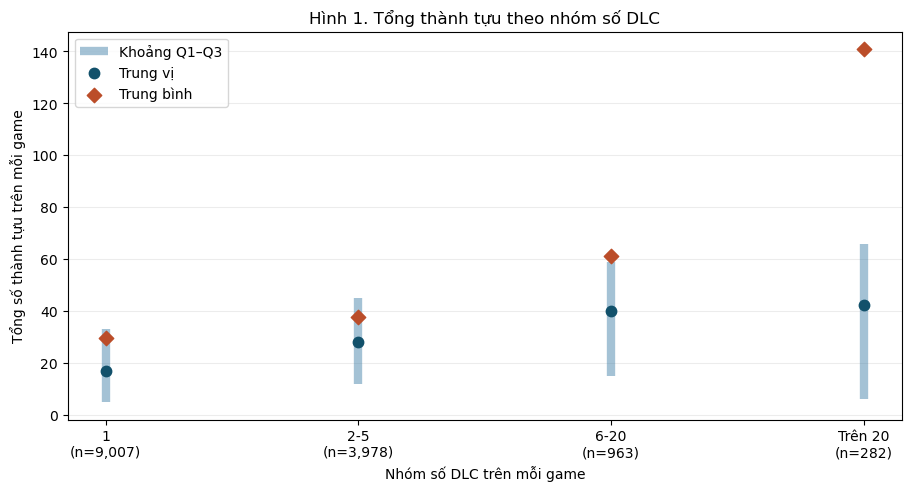

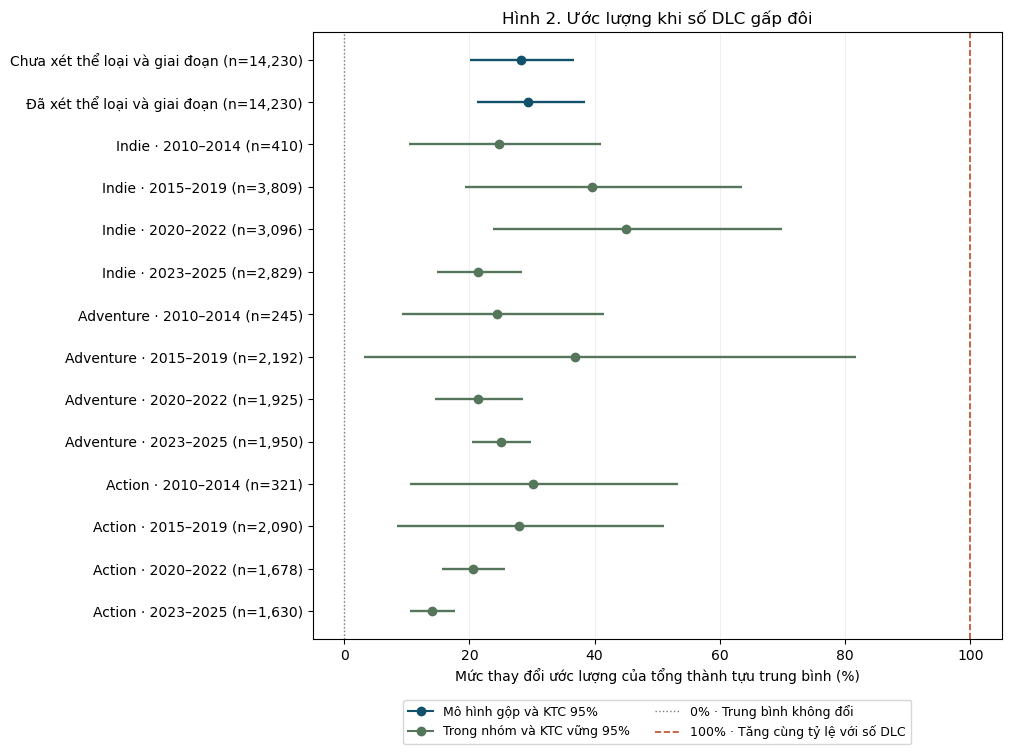

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.8), layout="constrained")
x = np.arange(len(groups))
ax.vlines(x, groups["q1"], groups["q3"], color="#3176A1",
          linewidth=6, alpha=0.44, label="Khoảng Q1–Q3")
ax.scatter(x, groups["median"], s=56, color="#12516B", zorder=3, label="Trung vị")
ax.scatter(x, groups["mean"], s=54, marker="D", color="#BB4D29", zorder=3, label="Trung bình")
ax.set_xticks(x, [f"{label}\n(n={n:,})" for label, n in zip(groups.index, groups["n"])])
ax.set_xlabel("Nhóm số DLC trên mỗi game")
ax.set_ylabel("Tổng số thành tựu trên mỗi game")
ax.set_title("Hình 1. Tổng thành tựu theo nhóm số DLC")
ax.legend(loc="upper left")
ax.grid(axis="y", alpha=0.23)
plt.show()

plot = pd.concat([overall, strata], ignore_index=True)
fig, ax = plt.subplots(figsize=(10, max(5.4, 0.42 * len(plot) + 1.55)), layout="constrained")
for i, row in plot.iterrows():
    color = "#12516B" if i < 2 else "#55765B"
    ax.hlines(i, row["KTC thấp (%)"], row["KTC cao (%)"], color=color, linewidth=1.7)
    ax.plot(row["Thay đổi (%)"], i, "o", color=color, markersize=6)

no_change_line = ax.axvline(0, color="#7A7A7A", linewidth=1, linestyle=":", label="0% · Trung bình không đổi")
proportional_line = ax.axvline(100, color="#BB4D29", linewidth=1.2, linestyle="--",
                               label="100% · Tăng cùng tỷ lệ với số DLC")
ax.set_yticks(range(len(plot)), [f"{r['Mô hình']} (n={r['N']:,})" for _, r in plot.iterrows()])
ax.invert_yaxis()
ax.set_xlabel("Mức thay đổi ước lượng của tổng thành tựu trung bình (%)")
ax.set_title("Hình 2. Ước lượng khi số DLC gấp đôi")
ax.grid(axis="x", alpha=0.2)
ax.legend(handles=[
    Line2D([0], [0], color="#12516B", marker="o", label="Mô hình gộp và KTC 95%"),
    Line2D([0], [0], color="#55765B", marker="o", label="Trong nhóm và KTC vững 95%"),
    no_change_line,
    proportional_line,
], loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=2, fontsize=9)
plt.show()

**Nhận xét sau hai hình**

- **Hình 1.** Các khoảng Q1–Q3 chồng lên nhau. Chẳng hạn, nhóm 6–20 DLC có khoảng 15–59 thành tựu, còn nhóm trên 20 DLC có khoảng 6–66. Tổng thành tựu dao động rộng ngay trong từng nhóm này.
- **Hình 2.** Vạch ngang càng dài thì ước lượng càng kém chính xác. Chẳng hạn, KTC của nhóm Adventure giai đoạn 2015–2019 rộng hơn KTC của nhóm Action giai đoạn 2023–2025.

#### 7. Kết quả và thảo luận

Mức tăng 29,4% là **ước lượng chung của mô hình gộp**. Nhà thiết kế có thể dùng con số này làm mốc khi đối chiếu hệ thống thành tựu giữa các game có đặc điểm tương đồng. Các ước lượng điểm trong 12 nhóm dao động từ 14,1% đến 45,0%. Khoảng dao động này mô tả các kết quả ước lượng, còn việc so sánh trực tiếp độ lớn giữa các nhóm cần một phép kiểm riêng.

Nhóm trên 20 DLC là trường hợp cần đọc cả trung bình lẫn trung vị. Một số game có tổng thành tựu rất cao, nên trung bình cao hơn nhiều so với mức của game ở giữa nhóm. Mục 8 kiểm tra xem kết luận thay đổi thế nào khi giới hạn các giá trị ở đuôi phân bố.

#### 8. Kiểm tra độ bền vững

Ước lượng lại trên ba tập con. Lần lượt giữ game có số DLC không vượt P99, giữ game có cả số DLC và thành tựu không vượt P99 tương ứng, rồi chỉ xét game có từ 2 DLC. Các ngưỡng P99 được tính từ toàn bộ mẫu phân tích. Bảng ghi số game còn lại và số bị loại ở từng cách lọc.

Cả bốn hàng của bảng, kể cả hàng **Toàn bộ mẫu**, dùng cùng các biến điều chỉnh và KTC vững HC0 ở mức 95% để đối chiếu trên cùng cơ sở.

In [5]:
p99_dlc = game["dlc_count"].quantile(0.99)
p99_ach = game["achievements"].quantile(0.99)
dlc_threshold = f"{p99_dlc:g}".replace(".", ",")
ach_threshold = f"{p99_ach:g}".replace(".", ",")
masks = {
    "Toàn bộ mẫu": np.ones(len(game), dtype=bool),
    f"DLC ≤ {dlc_threshold} (P99)": game["dlc_count"].le(p99_dlc).to_numpy(),
    f"DLC ≤ {dlc_threshold} và thành tựu ≤ {ach_threshold} (P99)":
        (game["dlc_count"].le(p99_dlc) & game["achievements"].le(p99_ach)).to_numpy(),
    "Chỉ game có từ 2 DLC": game["dlc_count"].ge(2).to_numpy(),
}
checks = []
with threadpool_limits(limits=1, user_api="blas"):
    for label, mask in masks.items():
        fit = fit_poisson(y[mask], x_adjusted[mask], start=adjusted.params)
        checks.append(result_row(label, int(mask.sum()), fit))
sensitivity = pd.DataFrame(checks)
sensitivity.insert(2, "Số game loại so với mẫu chính", len(game) - sensitivity["N"])
display(sensitivity.round(3))

,Mô hình,N,Số game loại so với mẫu chính,beta,beta thấp,beta cao,Thay đổi (%),KTC thấp (%),KTC cao (%)
0,Toàn bộ mẫu,14230,0,0.371,0.264,0.479,29.356,20.060,39.371
1,DLC ≤ 36 (P99),14095,135,0.284,0.175,0.393,21.729,12.880,31.271
2,DLC ≤ 36 và thành tựu ≤ 191 (P99),13972,258,0.269,0.248,0.290,20.515,18.769,22.287
3,Chỉ game có từ 2 DLC,5223,9007,0.423,0.286,0.560,34.058,21.903,47.425


**Nhận xét sau bảng**

Hàng **Toàn bộ mẫu** có cùng ước lượng điểm 29,4% với mô hình chính. KTC ở đây là **20,1–39,4%** theo HC0, còn KTC dùng cho kết quả chính là **21,3–38,5%** theo bootstrap. Hai cặp cận khác nhau vì dùng hai cách tính độ bất định.

- Giới hạn số DLC ở 36 (P99) cho mức tăng ước lượng **21,7%**. Giới hạn thêm tổng thành tựu ở 191 (P99) cho mức tăng **20,5%**, trên tập con đã loại các game có số đếm vượt ngưỡng.
- Khi chỉ giữ **5.223 game có từ 2 DLC**, mức tăng ước lượng là **34,1%**. Mức tăng cụ thể nhạy với cách lọc, nhưng cả ba KTC đều nằm giữa 0% và 100%.

#### 9. Giới hạn phân tích

- **Dữ liệu tại một thời điểm.** Ước lượng so sánh giữa các game trong bản ghi tháng 03/2025. Quy mô dự án, nhà phát triển và lịch phát hành DLC vẫn có thể liên quan đến cả số DLC lẫn số thành tựu. Kết quả mô tả mối liên hệ quan sát được.
- **Đơn vị đo.** `achievements` là tổng thành tựu cấp game, gồm những thành tựu có thể thuộc game gốc, DLC hoặc bản cập nhật. `dlc_count` đếm số gói. Hai cột này chưa cho biết lượng nội dung hay số thành tựu của từng gói.
- **Phạm vi áp dụng.** Mẫu chỉ bao phủ một phần game trên Steam. Phân tích theo nhóm chỉ bao gồm các nhãn và giai đoạn đủ dữ liệu. Các game có rất nhiều DLC ít hơn nhiều so với nhóm có một DLC, nên mức ước lượng chung cần được đọc cùng kết quả theo nhóm và bảng kiểm tra độ bền.

#### 10. Kết luận

Theo mô hình gộp trên **14.230 game có DLC**, sau khi xét thể loại và giai đoạn phát hành, số DLC gấp đôi đi cùng tổng thành tựu trung bình cao hơn **29,4%** (KTC bootstrap 95% **21,3–38,5%**). Mức tăng này thấp hơn mốc tăng cùng tỷ lệ 100%. Xu hướng thành tựu tăng chậm hơn số DLC xuất hiện ở cả **12 nhóm đủ điều kiện** khi so sánh các game cùng mang một nhãn thể loại và cùng giai đoạn phát hành, đồng thời giữ được qua ba phép kiểm độ bền.